# 01 — Fuel Price Analysis (Brent)

Source: FRED series `MCOILBRENTEU`, monthly Brent crude oil price (USD/barrel), Jan 2019 – Aug 2026.

Purpose: Free historical VLSFO prices are not available. Brent is used as a proxy for movements in marine fuel prices. This notebook inspects the data and produces `brent_monthly_processed.csv` for the Monte Carlo model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
raw_url = "https://github.com/Isakstevik/shipping-route-monte-carlo-V1/raw/refs/heads/main/data/raw/MCOILBRENTEU.xlsx"

brent_df = pd.read_excel(
    raw_url,
    sheet_name = "Monthly"
    )

In [3]:
brent_df.head()

,observation_date,MCOILBRENTEU
0,2019-01-01,59.41
1,2019-02-01,63.96
2,2019-03-01,66.14
3,2019-04-01,71.23
4,2019-05-01,71.32


In [4]:
brent_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  92 non-null     datetime64[ns]
 1   MCOILBRENTEU      92 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 1.6 KB


In [5]:
brent_df["MCOILBRENTEU"].describe()

,MCOILBRENTEU
count,92.000000
mean,74.362391
std,19.243473
min,18.380000
25%,64.155000
50%,74.260000
75%,83.980000
max,122.710000


In [6]:
brent_df.isna().sum()

,0
observation_date,0
MCOILBRENTEU,0


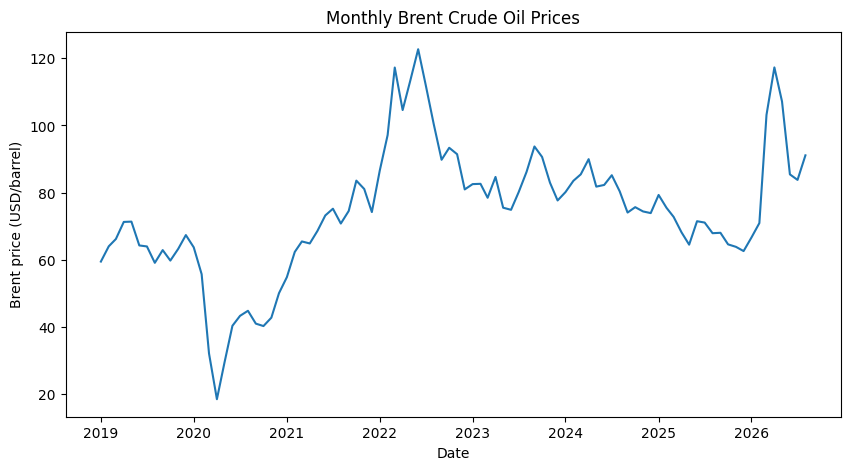

In [7]:
plt.figure(figsize = (10, 5))

plt.plot(
    brent_df["observation_date"],
    brent_df["MCOILBRENTEU"]
)

plt.xlabel("Date")
plt.ylabel("Brent price (USD/barrel)")
plt.title("Monthly Brent Crude Oil Prices")

plt.show()

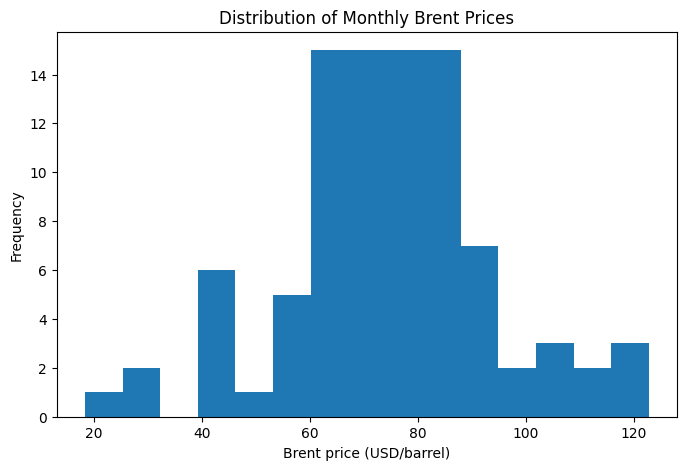

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    brent_df["MCOILBRENTEU"],
    bins = 15
)

plt.xlabel("Brent price (USD/barrel)")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Brent Prices")

plt.show()

## Monthly returns
Percentage change from the previous month. The first month has no previous value and is therefore NaN.

In [9]:
brent_df["monthly_return"] = (
    brent_df['MCOILBRENTEU'].pct_change()
)

In [10]:
brent_df.head()

,observation_date,MCOILBRENTEU,monthly_return
0,2019-01-01,59.41,NaN
1,2019-02-01,63.96,0.076586
2,2019-03-01,66.14,0.034084
3,2019-04-01,71.23,0.076958
4,2019-05-01,71.32,0.001264


In [11]:
brent_df['monthly_return'].describe()

,monthly_return
count,91.000000
mean,0.013305
std,0.132317
min,-0.425804
25%,-0.054195
50%,0.001768
75%,0.068989
max,0.598477


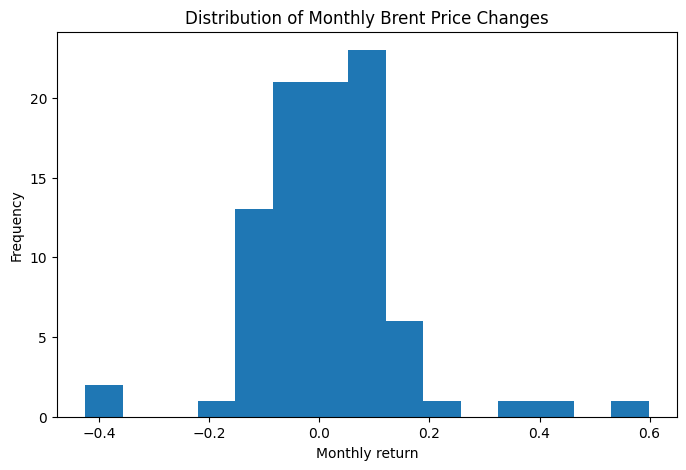

In [12]:
plt.figure(figsize=(8,5))

plt.hist(
    brent_df["monthly_return"].dropna(),
    bins = 15
)

plt.xlabel("Monthly return")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Brent Price Changes")

plt.show()

In [13]:
display(brent_df.nsmallest(3, "monthly_return"))
display(brent_df.nlargest(3, "monthly_return"))

,observation_date,MCOILBRENTEU,monthly_return
15,2020-04-01,18.38,-0.425804
14,2020-03-01,32.01,-0.424901
89,2026-06-01,85.40,-0.202912


,observation_date,MCOILBRENTEU,monthly_return
16,2020-05-01,29.38,0.598477
86,2026-03-01,103.13,0.454789
17,2020-06-01,40.27,0.370660


## Findings
- 92 monthly observations, no missing values.
- The largest moves are April 2020 (−42.6%) and May 2020 (+59.8%), during the COVID oil price collapse and rebound. These are real market events and are kept.
- Returns are fat-tailed, so a normal distribution would understate extreme moves.

**Note on use in the model:** The final Monte Carlo model uses Brent *levels*, not returns. Each simulation draws a historical month and scales the VLSFO baseline by Brent that month relative to the latest Brent. This allows freight rate and fuel price to be drawn from the same month (paired bootstrap). The returns analysis is kept here because it documents the volatility of fuel prices.

## Save processed data
The output file is uploaded to `data/processed/` in the repository.

In [14]:
brent_df.to_csv(
    "brent_monthly_processed.csv",
    index = False
)